<a target="_blank" href="https://colab.research.google.com/github/bettercodepaul/data-wrangling-praktikum/blob/master/Polars_Part_3.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Polars: The Turbo Boost for Dataframes - Part 3

Important links as a reminder:

- Homepage of Polars: https://www.pola.rs/
- User Guide: https://pola-rs.github.io/polars/user-guide/
- API Reference: https://pola-rs.github.io/polars/py-polars/html/reference/

## Installation + Set-Up

In [1]:
# Download utility module und data
import urllib.request
import os.path
UTILS_URL = "https://github.com/bettercodepaul/data-wrangling-praktikum/raw/master/utils.py"
urllib.request.urlretrieve(UTILS_URL, os.path.basename(UTILS_URL))
from utils import download_data, download_region_data
download_data()
download_region_data()

In [2]:
# install libraries
!uv pip install -qr requirements.txt

In [3]:
# import polars
import polars as pl
# output up to 60 characters per column and do not abbreviate floating point numbers
pl.Config(fmt_str_lengths=60, fmt_float="full")

In [4]:
# import exercises and utility functions
from utils import *
from exercises_en import *

In [5]:
# Load data from CSV file and parse date columns
df = pl.read_csv("spotify-charts-2017-2021-global-top200.csv.gz", try_parse_dates=True)
df.head(2) # output the first 2 rows

title,rank,date,artist,url,region,chart,trend,streams
str,i64,date,str,str,str,str,str,i64
"""Starboy""",1,2017-01-01,"""The Weeknd, Daft Punk""","""https://open.spotify.com/track/5aAx2yezTd8zXrkmtKl66Z""","""Global""","""top200""","""SAME_POSITION""",3135625
"""Closer""",2,2017-01-01,"""The Chainsmokers, Halsey""","""https://open.spotify.com/track/7BKLCZ1jbUBVqRi2FVlTVw""","""Global""","""top200""","""SAME_POSITION""",3015525


## When.Then.Otherwise

Sometimes you want to calculate an expression in certain cases like this and in other cases like that.

For this there are the methods `when.then.otherwise`, which correspond to an `if.then.else`.

In [6]:
df = pl.read_csv("spotify-charts-2017-2021-global-top200.csv.gz", try_parse_dates=True)

It then works like this:

In [7]:
(df
    .with_columns(
        pl.when(pl.col("date").dt.day().eq(14) & pl.col("date").dt.month().eq(2))
        .then(pl.col("streams"))
        .otherwise(pl.lit(0))
        .alias("valentinesStreams")
    )
    .filter(pl.col("title").eq("Starboy") & pl.col("date").dt.week().eq(7))
    .select("date", "streams", "valentinesStreams")
    .head(5)
)

date,streams,valentinesStreams
date,i64,i64
2017-02-13,2593043,0
2017-02-14,2483528,2483528
2017-02-15,2508046,0
2018-02-12,570694,0
2017-02-16,2529306,0


We could also recreate the trend column ourselves:

In [8]:
(df
    .join(
        # Determine rank from previous day
        df.select("url", pl.col("date").dt.offset_by("1d"), pl.col("rank").alias("previous_rank")),
        how="left",
        on=["url", "date"]
    )
    .with_columns(
        pl.when(pl.col("rank").lt(pl.col("previous_rank")))
        .then(pl.lit("MOVE_UP"))
        .otherwise(
            pl.when(pl.col("rank").gt(pl.col("previous_rank")))
            .then(pl.lit("MOVE_DOWN"))
            .otherwise(
                pl.when(pl.col("rank").eq(pl.col("previous_rank")))
                .then(pl.lit("SAME_POSITION"))
                .otherwise(pl.lit("NEW_ENTRY"))
            )
        ).alias("myTrend")
    )
    .select("title", "artist", "date", "trend", "myTrend")
    .sample(10)
)

title,artist,date,trend,myTrend
str,str,date,str,str
"""Shout Out to My Ex""","""Little Mix""",2017-02-05,"""SAME_POSITION""","""SAME_POSITION"""
"""Paradise""","""George Ezra""",2018-04-14,"""MOVE_UP""","""MOVE_UP"""
"""I Fall Apart""","""Post Malone""",2018-06-23,"""MOVE_UP""","""MOVE_UP"""
"""Get You The Moon (feat. Snøw)""","""Kina""",2020-10-23,"""MOVE_DOWN""","""MOVE_DOWN"""
"""Roses - Imanbek Remix""","""SAINt JHN""",2020-02-27,"""MOVE_DOWN""","""MOVE_DOWN"""
"""Starboy""","""The Weeknd, Daft Punk""",2021-03-29,"""MOVE_DOWN""","""MOVE_DOWN"""
"""death bed (coffee for your head)""","""Powfu, beabadoobee""",2020-07-27,"""MOVE_DOWN""","""MOVE_DOWN"""
"""lovely (with Khalid)""","""Billie Eilish""",2021-12-12,"""MOVE_UP""","""MOVE_UP"""
"""Yo x Ti, Tu x Mi""","""ROSALÍA, Ozuna""",2020-01-19,"""MOVE_DOWN""","""MOVE_DOWN"""


If it is only about replacing certain, single values with others, `replace` can also be very handy.

In [9]:
mapping = {
    "SAME_POSITION": "➡️",
    "NEW_ENTRY": "🆕",
    "MOVE_UP": "⬆️",
    "MOVE_DOWN": "⬇️"
}
(df
  .with_columns(pl.col("trend")
  .replace(mapping).alias("trendSymbol"))
  .group_by("trendSymbol")
  .len()
)

trendSymbol,len
str,u32
"""➡️""",47275
"""⬆️""",141400
"""⬇️""",156355
"""🆕""",17152


## Custom Expressions

### Please do not: `map_*`

The worst possible way to smuggle your own functions into a Polars query are the various map methods `map_rows`, `map_batches`, `map_elements` and `map_groups`, which execute a UDF (User Defined Function).

This should be avoided because performance suffers greatly.

### Expression Factories




A more elegant way to get modular code is to use custom methods that create new expressions and can be called e.g. with the `pipe` method.

Here is an example for the method `sum` for which there is no `min_count` parameter in Polars (but there is in Pandas). The `min_count` parameter determines how many values must be present at least for the sum to be formed.

In [10]:
def sum(expr: pl.Expr, min_count=0) -> pl.Expr:
    if min_count > 0:
        return pl.when(
            expr.is_not_null().sum().ge(pl.lit(min_count))
        ).then(expr.sum())
    else:
        return expr.sum()

In [11]:
# direct call to the method
pl.DataFrame({
    "value": [42, 43, None],
}).select(
    sum(pl.col("value"), min_count=2).alias("min_count=2"),
    sum(pl.col("value"), min_count=3).alias("min_count=3")
)

min_count=2,min_count=3
i64,i64
85,null


In [12]:
# call via pipe
pl.DataFrame({
    "value": [42, 43, None],
}).select(
    pl.col("value").pipe(sum, min_count=2).alias("min_count=2"),
    pl.col("value").pipe(sum, min_count=3).alias("min_count=3")
)

min_count=2,min_count=3
i64,i64
85,null


We can also register such methods in a separate namespace.

In [13]:
@pl.api.register_expr_namespace("special")
class Special:
    def __init__(self, expr: pl.Expr):
        self._expr = expr

    def sum(self, min_count=0) -> pl.Expr:
        if min_count > 0:
            return pl.when(
                self._expr.is_not_null().sum().ge(pl.lit(min_count))
            ).then(self._expr.sum())
        else:
            return self._expr.sum()

Now we can call the method within its own namespace "special".

In [14]:
pl.DataFrame({
    "value": [42, 43, None],
}).select(
    pl.col("value").special.sum(min_count=2).alias("min_count=2"),
    pl.col("value").special.sum(min_count=3).alias("min_count=3")
)

min_count=2,min_count=3
i64,i64
85,null


Further information is available here:

- [Expr.pipe](https://pola-rs.github.io/polars/py-polars/html/reference/expressions/api/polars.Expr.pipe.html)
- [DataFrame.pipe](https://pola-rs.github.io/polars/py-polars/html/reference/dataframe/api/polars.DataFrame.pipe.html)
- [Extending the API](https://pola-rs.github.io/polars/py-polars/html/reference/api.html)

## Lazy vs. Eager

Until now we have always used Polars in "eager mode". Each function call directly resulted in an operation on the data.

This has advantages when debugging queries, but prevents many optimizations that Polars can only use in "lazy mode".

There are two options for the "lazy mode".

### Eager Load + Lazy Query

If a data set is not too large, we can load it completely into memory, as we already know.

In [15]:
df = pl.read_csv("spotify-charts-2017-2021-global-top200.csv.gz")
type(df)

polars.dataframe.frame.DataFrame

By calling the `lazy` method we then switch to the "lazy mode". The execution of the query is now stopped and with each further call the query is only "formulated".

In [16]:
lazy_df = df.lazy()
type(lazy_df)

polars.lazyframe.frame.LazyFrame

In [17]:
# for a lazy dataframe the unoptimized query tree is printed
lazy_df.select("artist", "title").filter(pl.col("artist").eq("Dua Lipa"))

The plan is read from bottom to top. The Greek letters are from relational algebra. The letter π stands for the operation projection (`select`), σ for the operation selection (`filter`).

- Table π */9; σ -; means that all nine columns are read and no selection is made.
- π 2/9 means that two out of nine columns are projected
- FILTER BY is the filter from our query

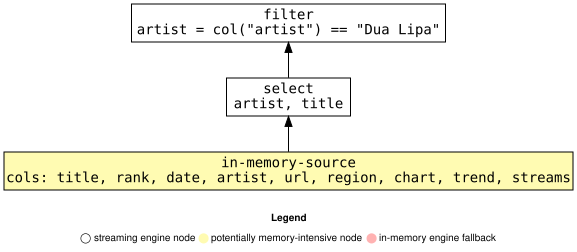

In [18]:
# with the method show_graph() we can output the optimized query
lazy_df.select("artist", "title").filter(pl.col("artist").eq("Dua Lipa")).show_graph()

Both projection and selection happen earlier in the optimized query plan.

The query is finally executed when we call the `collect` method. The result is then a normal dataframe again.

In [19]:
result = lazy_df.select("artist", "title").filter(pl.col("artist").eq("Dua Lipa")).collect()
result.sample(2)

artist,title
str,str
"""Dua Lipa""","""Physical"""
"""Dua Lipa""","""Don't Start Now"""


In [20]:
type(result)

polars.dataframe.frame.DataFrame

By doing this, Polars can perform optimizations before executing the query.

A selection of optimizations can be found here: https://pola-rs.github.io/polars/user-guide/lazy/optimizations/

### Lazy Load + Query

If it is not worth loading a data set completely into memory, we can also delay loading the data by using the IO methods named `scan_*` instead of `write_*`.

This works e.g. for files in CSV (`scan_csv`) and Parquet (`scan_parquet`) formats, but not for compressed CSVs.

So far we have always worked with a small dataset containing only the global top-200 charts (362k lines, 64 MB).

We can now switch to the real dataset that contains the Top-200 and Viral-50 charts for 70 different regions (26m rows, 4 GB).

In [21]:
df = pl.scan_parquet("spotify-charts-2017-2021.parquet")

Due to the optimized queries, only the data that is really needed is loaded from the file.

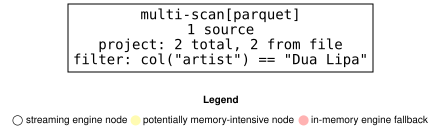

In [22]:
(df
    .select("artist", "title")
    .filter(pl.col("artist").eq("Dua Lipa"))
).show_graph()

Depending on the query, certain optimizations cannot be performed because they would change the result...

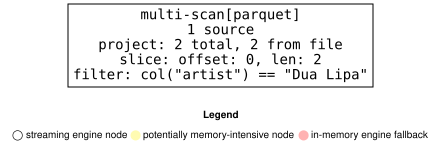

In [23]:
(df
    .head(2)
    .select("artist", "title")
    .filter(pl.col("artist").eq("Dua Lipa"))
).show_graph()

### Streaming

If the final result or even intermediate results of a query do not fit into RAM anymore, Polars has a streaming engine which can significantly reduce the required RAM and is used by default when using the lazy mode.

If the final result fits into RAM collect can be used and will materialize the final result into memory.

To write also a final result that does not fit into RAM anymore to disk, the methods `sink_parquet`, `sink_csv` and `sink_ipc` can be used.

In [24]:
# If the Jupyter kernel crashed, restart and run this line
import polars as pl
df = pl.scan_parquet("spotify-charts-2017-2021.parquet")

In [25]:
# fraction is the fraction of rows and influences the memory requirement
# 0.003 ~ 4 GB (should run with 8 GB RAM)
# 0.005 ~ 10 GB (should run with 16 GB RAM)
# 0.008 ~ 26 GB (should run with 32 GB RAM)
# 0.010 ~ 41 GB (should run with 64 GB RAM)
# 0.015 ~ 92 GB (should run with 128 GB RAM)
fraction = 0.008
row_count = round(26173514*fraction)
high_mem_query = (
    df.head(row_count).join(df.head(row_count), on="artist")
    .filter(
        pl.col("url").ne(pl.col("url_right")) &
        pl.col("date").gt(pl.col("date_right")) &
        pl.col("trend").eq("NEW_ENTRY") &
        pl.col("trend_right").eq("NEW_ENTRY")
    )
    .group_by("url").agg((pl.col("date") - pl.col("date_right")).min().alias("durationBetweenNewEntries"))
    .select(pl.col("durationBetweenNewEntries").mean())
)
print(f"Cross-product of {row_count:_} rows would contain {row_count**2:_} rows.")
print(f"Estimated size for the intermediate join result is {6e-10*row_count**2:.2f} GB.")

Cross-product of 209_388 rows would contain 43_843_334_544 rows.
Estimated size for the intermediate join result is 26.31 GB.


In [26]:
# try different fractions with engine="streaming" or engine="in-memory"
high_mem_query.collect(engine="streaming")

durationBetweenNewEntries
duration[μs]
106d 17h 27m 5s 373134µs


When a query can be executed in streaming mode the operations will be inside white "streaming engine" nodes. If some nodes can not be easily streamed you will see them either in a yellow "potentially memory-intensive" node or a red
"in-memory engine fallback" node.

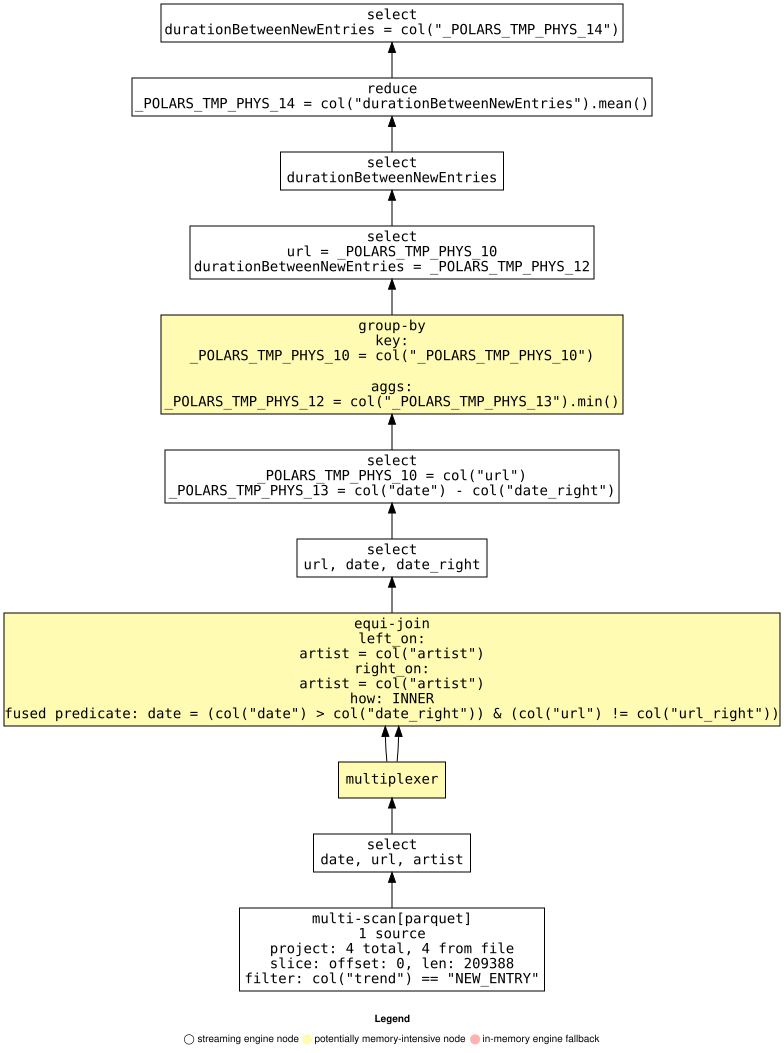

In [27]:
high_mem_query.show_graph(engine="streaming")

## Exercises

In [28]:
df = (
    pl.scan_parquet("spotify-charts-2017-2021.parquet")
    .with_columns(pl.col("streams").cast(pl.Int64))
)

### Question 21

In [29]:
q21.question()


Identify the 10 regions with the most streams.
    


In [47]:
q21_df = (df
          .group_by("region")
          .agg(pl.col("streams").sum())
          .top_k(10, by="streams")
          .collect())


In [49]:
q21.check(q21_df)

"✅ It might have taken a few tries, but you're unstoppable! 😅👊"

### Question 22

In [50]:
q22.question()


Additionally load the file region-info.csv and determine now the 10 regions with
the most streams relative to the population.
    


In [57]:
q22_df = (df.group_by("region")
    .agg(pl.col("streams").sum())
    .join(pl.scan_csv("region-info.csv"),on = "region")
    .with_columns(pl.col("streams")/pl.col("population"))
    .top_k(10,by="streams")
    .collect()
)

In [58]:
q22.check(q22_df)

"✅ Wow, first try and you nailed it! You're a natural problem-solver! 🎉👏"

### Question 23

In [59]:
q23.question()


Determine the different values for the "chart" column.
    


In [61]:
q23_df = df.select(pl.col("chart").unique()).collect()

In [62]:
q23.check(q23_df)

"✅ Wow, first try and you nailed it! You're a natural problem-solver! 🎉👏"

### Question 24

In [63]:
q24.question()


Calculate per continent for how many Christmases there are entries for the "top200" (on both
on December 24 and 25). Call the column with the years "xmasYears".
    


In [65]:
q24_df = (df.filter(pl.col("chart").eq("top200") & pl.col("date").dt.month().eq(12) & pl.col("date").dt.day().is_between(24, 25))
    .join(pl.scan_csv("region-info.csv"), on="region")
    .group_by("continent")
    .agg(pl.col("date").dt.year().n_unique().alias("xmasYears"))
    .collect()
)

In [66]:
q24.check(q24_df)

"✅ Wow, first try and you nailed it! You're a natural problem-solver! 🎉👏"

### Question 25

In [ ]:
q25.question()

In [ ]:
region_df = pl.scan_csv("region-info.csv")
xmasYears_per_continent = ...


In [ ]:
q25_df = ...

In [ ]:
q25.check(q25_df)